<a href="https://colab.research.google.com/github/Kireeti2808/agri_doctor/blob/main/Agri_Doctor_full_evaluation_autofix_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
# 0. Settings (you can leave these)
RICE_SEEDS = [42, 7, 2024]        # repeated training runs for mean ± sd
GEMINI_SAMPLE_PER_CROP = 60       # field photos per crop sent to Gemini (free tier: keep <= 80)
MAX_IMAGES_PER_SET = 1500         # cap per evaluation set (keeps runtime bounded)
DUP_THRESHOLD = 4                 # perceptual-hash bits; <= this counts as a copy of a training image

In [22]:
# 1. GPU, Google Drive, repository, packages
!nvidia-smi -L || echo "NO GPU - set Runtime > Change runtime type > T4 GPU, then Run all again"
import os, sys, json, time, shutil, subprocess, zipfile
from pathlib import Path
from google.colab import drive
try:
    drive.mount('/content/drive'); BASE = Path('/content/drive/MyDrive')
except Exception as e:
    print('Drive not mounted (results kept in this session only):', e); BASE = Path('/content')
OUT = BASE / 'agri_results_v2'; OUT.mkdir(parents=True, exist_ok=True)
EXT = BASE / 'agri_external'; EXT.mkdir(parents=True, exist_ok=True)
if not Path('/content/agri_doctor').exists():
    !git clone -q https://github.com/Kireeti2808/agri_doctor /content/agri_doctor
%cd /content/agri_doctor
!pip install -q kagglehub gdown scikit-learn scipy google-genai
!apt-get -qq install -y unrar p7zip-full > /dev/null 2>&1 || true
sys.path.insert(0, '/content/agri_doctor'); sys.path.insert(0, '/content')
import tensorflow as tf
COMMIT = subprocess.check_output(['git', '-C', '/content/agri_doctor', 'rev-parse', 'HEAD']).decode().strip()
print('repo commit', COMMIT, '| TF', tf.__version__, '| GPU', tf.config.list_physical_devices('GPU'))
print('external files in Drive/agri_external:', [p.name for p in EXT.iterdir()])
def done(name): return (OUT / name).exists()
def save(name, obj): json.dump(obj, open(OUT / name, 'w'), indent=1, default=str)

GPU 0: Tesla T4 (UUID: GPU-07eeac5e-9f4e-c78e-eca3-31d9f856eb41)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/agri_doctor
repo commit 4bb2682aa763ad5579be707a79b9a781c1ac414a | TF 2.21.0 | GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
external files in Drive/agri_external: []


In [23]:
%%writefile /content/exp_lib.py
"""Agri-Doctor Pro experiment helpers (data assembly, inference with the app's
own decision code, and statistics). Pure numpy/scipy apart from agri_core."""
import json
import math
import random
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps

import agri_core as ac

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}


# ------------------------------------------------------------------ data
def norm(s):
    return re.sub(r"[^a-z0-9]+", "_", str(s).lower()).strip("_")


def list_images(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT)


def ahash(path, size=8):
    with Image.open(path) as im:
        px = np.asarray(im.convert("L").resize((size, size), Image.Resampling.BILINEAR), dtype=np.float32)
    return np.packbits(px.flatten() > px.mean())


def hash_many(paths):
    out, ok = [], []
    for p in paths:
        try:
            out.append(ahash(p)); ok.append(p)
        except Exception:
            pass
    return (np.stack(out) if out else np.zeros((0, 8), np.uint8)), ok


def min_hamming(train_h, h):
    if len(train_h) == 0:
        return 64
    return int(np.unpackbits(np.bitwise_xor(train_h, h), axis=1).sum(1).min())


def dedupe_against(items, train_paths, threshold=4):
    """Drop external images that are (near-)copies of any training image."""
    train_h, _ = hash_many(train_paths)
    kept, removed = [], []
    for path, label in items:
        try:
            h = ahash(path)
        except Exception:
            continue
        (removed if min_hamming(train_h, h) <= threshold else kept).append((path, label))
    return kept, removed


def collect_by_keywords(root, rules, require=None, exclude=()):
    """rules: list of (keywords tuple, label). A file is labelled by the first
    rule whose keywords all occur in its normalised parent-path; `require`
    keywords must occur somewhere in the path; `exclude` keywords must not."""
    items, unmatched = [], Counter()
    root = Path(root)
    for p in list_images(root):
        rel = p.relative_to(root)
        path_text = norm(str(rel.parent))
        full = norm(str(rel))
        if require and not all(r in full for r in require):
            continue
        if any(x in full for x in exclude):
            continue
        label = None
        for keys, lab in rules:
            if all(k in path_text for k in keys):
                label = lab
                break
        if label is None:
            unmatched[p.parent.name] += 1
            continue
        if label != "SKIP":
            items.append((p, label))
    return items, dict(unmatched)


# ------------------------------------------------------------- inference
def old_rule(quads, healthy_label):
    """First app version: most frequent non-healthy quadrant label above 50%."""
    bad = [r["label"] for r in quads.values()
           if r["conf"] > ac.DETECTION_THRESHOLD and ac.label_kind(r["label"]) != "healthy"]
    return Counter(bad).most_common(1)[0][0] if bad else healthy_label


def run_image(img, true_label, true_crop, model_crop, interp, classes, router=None, tag=""):
    """Everything the app computes for one photo, plus TTA predictions."""
    img = ImageOps.exif_transpose(img).convert("RGB")
    probs = ac.predict_image(img, interp).astype(float)
    ac.check_probabilities(probs, model_crop)
    whole = ac.classify_image(img, interp, classes, model_crop)
    quads = ac.analyze_quadrants(img, interp, classes, model_crop)
    s = ac.summarize_diagnosis(whole, quads)
    tta = [ac.predict_image(t, interp).astype(float)
           for t in (ImageOps.mirror(img), ImageOps.flip(img))]
    healthy = next(c for c in classes if "Healthy" in c)
    row = {
        "tag": tag, "true": true_label, "true_crop": true_crop, "model_crop": model_crop,
        "probs": [round(float(x), 6) for x in probs],
        "pred": whole["label"], "conf": whole["conf"],
        "agreement": s["agreement"], "needs_review": s["needs_review"],
        "verdict_kind": s["verdict_kind"], "pred_old": old_rule(quads, healthy),
        "tta_probs": [[round(float(x), 6) for x in t] for t in tta],
    }
    if router is not None:
        r = ac.route_crop(ac.predict_image(img, router))
        row.update({"router_crop": r["crop"], "router_conf": r["confidence"],
                    "router_review": r["needs_review"]})
    return row


# ------------------------------------------------------------ statistics
def wilson(k, n, z=1.959964):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def pct(k, n):
    lo, hi = wilson(k, n)
    return {"k": int(k), "n": int(n), "pct": round(100 * k / n, 2) if n else None,
            "ci95": [round(100 * lo, 1), round(100 * hi, 1)] if n else None}


def mcnemar_exact(a_ok, b_ok):
    from scipy.stats import binomtest
    b = sum(1 for x, y in zip(a_ok, b_ok) if x and not y)
    c = sum(1 for x, y in zip(a_ok, b_ok) if y and not x)
    p = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
    return {"a_only_correct": b, "b_only_correct": c, "p_exact": float(p)}


def risk_coverage(score, correct):
    """Sort by descending confidence score; return coverage, selective risk."""
    score = np.asarray(score, float); correct = np.asarray(correct, bool)
    order = np.argsort(-score, kind="stable")
    c = correct[order]
    n = len(c)
    cov = np.arange(1, n + 1) / n
    risk = np.cumsum(~c) / np.arange(1, n + 1)
    return cov, risk


def aurc(score, correct):
    cov, risk = risk_coverage(score, correct)
    return float(risk.mean())


def bootstrap(fn, n, reps=1000, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(reps):
        idx = rng.integers(0, n, n)
        v = fn(idx)
        if v is not None and not (isinstance(v, float) and math.isnan(v)):
            vals.append(v)
    if not vals:
        return None
    return [round(float(np.percentile(vals, 2.5)), 4), round(float(np.percentile(vals, 97.5)), 4)]


def ece(probs, labels, bins=15):
    probs = np.asarray(probs, float); labels = np.asarray(labels)
    conf = probs.max(1); pred = probs.argmax(1); acc = (pred == labels)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)


def _softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def fit_temperature(probs, labels):
    from scipy.optimize import minimize_scalar
    logits = np.log(np.clip(np.asarray(probs, float), 1e-12, 1))
    labels = np.asarray(labels)

    def nll(t):
        p = _softmax(logits / t)
        return -np.log(np.clip(p[np.arange(len(labels)), labels], 1e-12, 1)).mean()
    return float(minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x)


def apply_temperature(probs, t):
    return _softmax(np.log(np.clip(np.asarray(probs, float), 1e-12, 1)) / t)


def crossfit_temperature_ece(probs, labels, seed=0):
    """2-fold cross-fitted temperature scaling on the evaluation set itself."""
    n = len(labels); idx = np.random.default_rng(seed).permutation(n)
    halves = [idx[: n // 2], idx[n // 2:]]
    out = np.zeros((n, np.asarray(probs).shape[1])); temps = []
    probs = np.asarray(probs, float); labels = np.asarray(labels)
    for a, b in [(0, 1), (1, 0)]:
        t = fit_temperature(probs[halves[a]], labels[halves[a]]); temps.append(t)
        out[halves[b]] = apply_temperature(probs[halves[b]], t)
    return ece(out, labels), temps


def scores_for(rows, classes):
    P = np.array([r["probs"] for r in rows])
    srt = np.sort(P, 1)
    T = np.array([r["tta_probs"] for r in rows])          # n x 2 x C
    pred = P.argmax(1)
    tta_agree = (T.argmax(2) == pred[:, None]).sum(1)      # 0..2
    tta_mean_conf = (T.mean(1) * 0.5 + P * 0.5)[np.arange(len(P)), pred]
    ent = -(P * np.log(np.clip(P, 1e-12, 1))).sum(1)
    return {
        "max_softmax": P.max(1),
        "margin": srt[:, -1] - srt[:, -2],
        "neg_entropy": -ent,
        "tta_mean_conf": tta_mean_conf,
        "tta_agree_plus_conf": tta_agree + P.max(1),
        "quadrant_agree_plus_conf": np.array([r["agreement"] for r in rows]) + P.max(1),
        "gate_pass_plus_conf": np.array([0 if r["needs_review"] else 1 for r in rows]) + P.max(1),
    }


def analyse(rows, classes, reps=1000):
    """Full analysis for one model on one evaluation set."""
    from sklearn.metrics import confusion_matrix, f1_score
    rows = [r for r in rows if r["true"] in classes]
    n = len(rows)
    if n == 0:
        return {"n": 0}
    y = np.array([classes.index(r["true"]) for r in rows])
    P = np.array([r["probs"] for r in rows])
    pred = P.argmax(1)
    correct = pred == y
    present = sorted(set(y.tolist()))
    res = {"n": n, "class_counts": {classes[i]: int((y == i).sum()) for i in present}}
    res["accuracy"] = pct(int(correct.sum()), n)
    res["macro_f1_present_classes"] = round(float(f1_score(y, pred, labels=present, average="macro", zero_division=0)), 4)
    res["per_class_recall"] = {classes[i]: pct(int(((pred == i) & (y == i)).sum()), int((y == i).sum())) for i in present}
    res["confusion"] = {"labels": classes, "matrix": confusion_matrix(y, pred, labels=list(range(len(classes)))).tolist()}
    res["predicted_kind"] = dict(Counter(ac.label_kind(classes[p]) for p in pred))
    old_ok = [r["pred_old"] == r["true"] for r in rows]
    res["old_quadrant_vote_accuracy"] = pct(sum(old_ok), n)
    res["new_vs_old_mcnemar"] = mcnemar_exact(correct.tolist(), old_ok)
    crop_rows = [r for r in rows if "router_crop" in r and "Weed" not in r["true"]]
    if crop_rows:
        m = len(crop_rows)
        res["router"] = {"crop_leaf_images": m, "called": dict(Counter(r["router_crop"] for r in crop_rows)),
                         "correct_crop": pct(sum(r["router_crop"] == r["true_crop"] for r in crop_rows), m),
                         "auto_accepted_wrong_crop": pct(sum((not r["router_review"]) and r["router_crop"] != r["true_crop"] for r in crop_rows), m)}
    # the app's review gate as an operating point
    flag = np.array([r["needs_review"] for r in rows])
    keep = ~flag
    err = ~correct
    gate = {"flagged": pct(int(flag.sum()), n),
            "errors_caught": pct(int((flag & err).sum()), int(err.sum())),
            "correct_flagged": pct(int((flag & correct).sum()), int(correct.sum())),
            "accuracy_unflagged": pct(int((keep & correct).sum()), int(keep.sum()))}
    # matched-coverage comparison with plain max-softmax thresholding
    cov = keep.mean()
    sc = scores_for(rows, classes)
    if 0 < keep.sum() < n:
        k = int(keep.sum())
        def matched(idx):
            c = correct[idx]; f = flag[idx]; m = sc["max_softmax"][idx]
            kk = int((~f).sum())
            if kk == 0 or kk == len(idx):
                return None
            top = np.argsort(-m, kind="stable")[:kk]
            return float(c[~f].mean() - c[top].mean())
        top = np.argsort(-sc["max_softmax"], kind="stable")[:k]
        gate["msp_accuracy_at_same_coverage"] = pct(int(correct[top].sum()), k)
        gate["gate_minus_msp_accuracy"] = round(float(correct[keep].mean() - correct[top].mean()), 4)
        gate["gate_minus_msp_ci95"] = bootstrap(matched, n, reps)
    gate["coverage"] = round(float(cov), 4)
    res["review_gate"] = gate
    # selective prediction baselines
    res["aurc_lower_is_better"] = {}
    for name, s in sc.items():
        res["aurc_lower_is_better"][name] = {
            "aurc": round(aurc(s, correct), 4),
            "ci95": bootstrap(lambda idx, s=s: aurc(s[idx], correct[idx]), n, reps)}
    res["risk_at_coverage"] = {}
    for name, s in sc.items():
        cov_, risk_ = risk_coverage(s, correct)
        res["risk_at_coverage"][name] = {str(c): round(float(risk_[max(0, int(math.ceil(c * n)) - 1)]), 4) for c in (0.5, 0.7, 0.8, 0.9, 1.0)}
    # calibration
    res["ece_raw"] = round(ece(P, y), 4)
    try:
        e, temps = crossfit_temperature_ece(P, y)
        res["ece_temperature_scaled_crossfit"] = round(e, 4)
        res["temperatures"] = [round(t, 3) for t in temps]
    except Exception as ex:
        res["ece_temperature_scaled_crossfit"] = str(ex)
    return res


# ---------------------------------------------------------------- gemini
def gemini_eval(rows_by_key, images_by_key, crop_of, api_key, model, out_path, per_crop=60,
                sleep_s=7.0, seed=0, log=print):
    """Blind Gemini assessment on a stratified sample, resumable via out_path."""
    import time
    done = {}
    if Path(out_path).exists():
        done = {d["key"]: d for d in json.load(open(out_path))}
    rng = random.Random(seed)
    by_crop = defaultdict(list)
    for key, row in rows_by_key.items():
        by_crop[crop_of(row)].append(key)
    sample = []
    for crop, keys in sorted(by_crop.items()):
        keys = sorted(keys); rng.shuffle(keys)
        sample += keys[:per_crop]
    for i, key in enumerate(sample):
        if key in done:
            continue
        row = rows_by_key[key]
        img = ImageOps.exif_transpose(Image.open(images_by_key[key])).convert("RGB")
        out = ac.assess_leaf_image(ac.image_for_assessment(img), api_key, model)
        rec = {"key": key, "ok": out.get("ok", False)}
        if out.get("ok"):
            a = out["assessment"]
            summary = {"primary": row["pred"], "verdict_kind": row["verdict_kind"]}
            cmp_ = ac.compare_assessments(row["model_crop"], summary, a)
            rec.update({"g_crop": a["crop"], "g_label": a["closest_label"], "g_certainty": a["certainty"],
                        "category": cmp_["category"], "supports_prescription": cmp_["supports_prescription"]})
        else:
            rec["error"] = str(out)[:300]
        done[key] = rec
        json.dump(list(done.values()), open(out_path, "w"), indent=1)
        if i % 10 == 0:
            log(f"gemini {i}/{len(sample)}")
        time.sleep(sleep_s)
    return list(done.values())


def gemini_analyse(records, rows_by_key):
    from scipy.stats import fisher_exact
    recs = [r for r in records if r.get("ok")]
    out = {"assessed": len(recs), "failed_calls": sum(1 for r in records if not r.get("ok"))}
    if not recs:
        return out
    ml_ok = [rows_by_key[r["key"]]["pred"] == rows_by_key[r["key"]]["true"] for r in recs]
    g_ok = [r["g_label"] == rows_by_key[r["key"]]["true"] for r in recs]
    crop_ok = [r["g_crop"] == rows_by_key[r["key"]]["true_crop"] for r in recs]
    out["ml_accuracy_on_sample"] = pct(sum(ml_ok), len(recs))
    out["gemini_label_accuracy"] = pct(sum(g_ok), len(recs))
    out["gemini_crop_accuracy"] = pct(sum(crop_ok), len(recs))
    cats = Counter(r["category"] for r in recs)
    out["categories"] = dict(cats)
    out["ml_accuracy_by_category"] = {c: pct(sum(o for o, r in zip(ml_ok, recs) if r["category"] == c), n)
                                      for c, n in cats.items()}
    agree = [r["category"] == ac.AGREEMENT for r in recs]
    a = sum(o and g for o, g in zip(ml_ok, agree)); b = sum((not o) and g for o, g in zip(ml_ok, agree))
    c = sum(o and not g for o, g in zip(ml_ok, agree)); d = sum((not o) and not g for o, g in zip(ml_ok, agree))
    out["agreement_vs_correct_2x2"] = [[a, b], [c, d]]
    out["fisher_p"] = float(fisher_exact([[a, b], [c, d]])[1])
    gate = [rows_by_key[r["key"]]["needs_review"] for r in recs]
    errs = [not o for o in ml_ok]
    vlm_flag = [r["category"] not in (ac.AGREEMENT,) for r in recs]
    out["errors_caught_by_gate_only"] = pct(sum(g and e for g, e in zip(gate, errs)), max(1, sum(errs)))
    out["errors_caught_by_vlm_only"] = pct(sum(v and e for v, e in zip(vlm_flag, errs)), max(1, sum(errs)))
    out["errors_caught_by_gate_or_vlm"] = pct(sum((g or v) and e for g, v, e in zip(gate, vlm_flag, errs)), max(1, sum(errs)))
    out["results_flagged_by_gate_or_vlm"] = pct(sum(g or v for g, v in zip(gate, vlm_flag)), len(recs))
    out["prescription_on_wrong_diagnosis"] = pct(sum(r["supports_prescription"] and e for r, e in zip(recs, errs)), len(recs))
    return out


# ------------------------------------------------- conformal methods
def _cp_upper(k, n, delta):
    """Clopper-Pearson one-sided upper bound on a binomial rate."""
    from scipy.stats import beta
    return 1.0 if k >= n else float(beta.ppf(1 - delta, k + 1, n - k))


def selective_risk_control(score, correct, alpha, delta=0.1, splits=20, seed=0):
    """Learn-then-test style: on a calibration half pick the lowest threshold whose
    Clopper-Pearson upper bound on selective error is <= alpha (fixed-sequence
    test from the most confident end); report risk and coverage on the other half."""
    score = np.asarray(score, float); correct = np.asarray(correct, bool)
    n = len(score); rng = np.random.default_rng(seed); out = []
    for _ in range(splits):
        idx = rng.permutation(n); cal, te = idx[: n // 2], idx[n // 2:]
        order = cal[np.argsort(-score[cal], kind="stable")]
        thr = None; errs = 0
        for j, i in enumerate(order, 1):
            errs += int(not correct[i])
            if _cp_upper(errs, j, delta) <= alpha:
                thr = score[i]
            elif j >= 10:
                # fixed-sequence testing stops at the first failure after a minimal sample
                if thr is not None:
                    break
        if thr is None:
            out.append({"coverage": 0.0, "risk": None}); continue
        keep = score[te] >= thr
        out.append({"coverage": float(keep.mean()),
                    "risk": float((~correct[te][keep]).mean()) if keep.any() else None})
    covs = [o["coverage"] for o in out]; risks = [o["risk"] for o in out if o["risk"] is not None]
    return {"alpha": alpha, "delta": delta, "splits": splits,
            "coverage_mean": round(float(np.mean(covs)), 4), "coverage_sd": round(float(np.std(covs)), 4),
            "test_risk_mean": round(float(np.mean(risks)), 4) if risks else None,
            "risk_violations": int(sum(r > alpha for r in risks)), "splits_with_any_coverage": len(risks)}


def conformal_sets(probs, labels, alpha=0.1, splits=20, seed=0):
    """Split-conformal (LAC) prediction sets: coverage guarantee 1-alpha."""
    P = np.asarray(probs, float); y = np.asarray(labels); n = len(y)
    rng = np.random.default_rng(seed); cov, size, single_correct = [], [], []
    for _ in range(splits):
        idx = rng.permutation(n); cal, te = idx[: n // 2], idx[n // 2:]
        s = 1 - P[cal, y[cal]]; m = len(cal)
        q = np.quantile(s, min(1.0, math.ceil((m + 1) * (1 - alpha)) / m), method="higher")
        sets = (1 - P[te]) <= q
        cov.append(float(sets[np.arange(len(te)), y[te]].mean()))
        size.append(float(sets.sum(1).mean()))
        single = sets.sum(1) == 1
        single_correct.append(float(single.mean()))
    return {"alpha": alpha, "target_coverage": 1 - alpha,
            "empirical_coverage_mean": round(float(np.mean(cov)), 4), "coverage_sd": round(float(np.std(cov)), 4),
            "mean_set_size": round(float(np.mean(size)), 3), "share_single_label_sets": round(float(np.mean(single_correct)), 4)}


# --------------------------------------------- learned combined gate
GATE_FEATURES = ["max_softmax", "margin", "neg_entropy", "tta_mean_conf", "tta_agree", "quadrant_agree", "gate_pass"]


def gate_features(rows, classes, gemini=None):
    P = np.array([r["probs"] for r in rows]); srt = np.sort(P, 1); pred = P.argmax(1)
    T = np.array([r["tta_probs"] for r in rows])
    feats = np.column_stack([
        P.max(1), srt[:, -1] - srt[:, -2], (P * np.log(np.clip(P, 1e-12, 1))).sum(1),
        (T.mean(1) * 0.5 + P * 0.5)[np.arange(len(P)), pred], (T.argmax(2) == pred[:, None]).sum(1),
        [r["agreement"] for r in rows], [0 if r["needs_review"] else 1 for r in rows]])
    names = list(GATE_FEATURES)
    if gemini is not None:
        cats = ["Agreement", "Partial agreement", "Disagreement", "Uncertain"]
        feats = np.column_stack([feats] + [[1.0 if gemini.get(r["tag"]) == c else 0.0 for r in rows] for c in cats])
        names += ["gemini_" + c.lower().replace(" ", "_") for c in cats]
    y = np.array([classes.index(r["true"]) for r in rows]); correct = pred == y
    return feats, correct, names


def learned_gate_cv(X, correct, folds=5, seed=0):
    """Cross-validated logistic-regression gate; returns out-of-fold scores."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    oof = np.zeros(len(correct))
    if correct.all() or (~correct).all() or min(correct.sum(), (~correct).sum()) < folds:
        return None
    for tr, te in StratifiedKFold(folds, shuffle=True, random_state=seed).split(X, correct):
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
        m.fit(X[tr], correct[tr]); oof[te] = m.predict_proba(X[te])[:, 1]
    return oof


def compare_gates(X, correct, names, reps=1000):
    oof = learned_gate_cv(X, correct)
    res = {"n": int(len(correct)), "errors": int((~correct).sum())}
    if oof is None:
        res["note"] = "too few errors or correct cases for 5-fold cross-validation"; return res
    msp = X[:, names.index("max_softmax")]
    res["aurc_max_softmax"] = round(aurc(msp, correct), 4)
    res["aurc_learned_gate"] = round(aurc(oof, correct), 4)
    res["aurc_difference_learned_minus_msp"] = round(res["aurc_learned_gate"] - res["aurc_max_softmax"], 4)
    res["difference_ci95"] = bootstrap(lambda i: aurc(oof[i], correct[i]) - aurc(msp[i], correct[i]), len(correct), reps)
    for a in (0.05, 0.10):
        res[f"risk_control_alpha{a}_msp"] = selective_risk_control(msp, correct, a)
        res[f"risk_control_alpha{a}_learned"] = selective_risk_control(oof, correct, a)
    return res


def leave_one_set_out(sets_X, sets_c):
    """Train the gate on all other field sets, test on the held-out one."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    out = {}
    for held in sets_X:
        tr = [k for k in sets_X if k != held]
        if not tr:
            continue
        Xtr = np.vstack([sets_X[k] for k in tr]); ctr = np.concatenate([sets_c[k] for k in tr])
        if ctr.all() or (~ctr).all():
            continue
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(Xtr, ctr)
        s = m.predict_proba(sets_X[held])[:, 1]; c = sets_c[held]
        out[held] = {"trained_on": tr, "aurc_learned": round(aurc(s, c), 4),
                     "aurc_max_softmax": round(aurc(sets_X[held][:, 0], c), 4)}
    return out


# ------------------------------------------------ few-shot adaptation
def few_shot_curve(lab_X, lab_y, field_X, field_y, shots=(0, 5, 10, 20), repeats=5, seed=0):
    """Same frozen-backbone embeddings; linear head trained on lab images plus k
    field images per class; tested on the remaining field images."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    rng = np.random.default_rng(seed); classes = sorted(set(field_y.tolist())); out = {}
    for k in shots:
        accs = []
        for r in range(repeats if k else 1):
            pick = []
            for c in classes:
                idx = np.where(field_y == c)[0]
                if k:
                    if len(idx) <= k:
                        continue
                    pick += rng.choice(idx, k, replace=False).tolist()
            pick = np.array(pick, int); rest = np.setdiff1d(np.arange(len(field_y)), pick)
            Xtr = np.vstack([lab_X, field_X[pick]]) if len(pick) else lab_X
            ytr = np.concatenate([lab_y, field_y[pick]]) if len(pick) else lab_y
            m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0))
            m.fit(Xtr, ytr)
            accs.append(float((m.predict(field_X[rest]) == field_y[rest]).mean()))
        out[str(k)] = {"accuracy_mean": round(float(np.mean(accs)), 4),
                       "accuracy_sd": round(float(np.std(accs)), 4), "repeats": len(accs)}
    return out

Overwriting /content/exp_lib.py


## Part 1 — Rice retraining (3 seeds)

In [24]:
import kagglehub, exp_lib as ex, agri_core as ac
from agri_core import RICE_CLASSES
rice_root = Path(kagglehub.dataset_download('anshulm257/rice-disease-dataset'))
weed_root = Path(kagglehub.dataset_download('fpeccia/weed-detection-in-soybean-crops'))
rice_data = rice_root
while len([p for p in rice_data.iterdir() if p.is_dir()]) == 1:
    rice_data = [p for p in rice_data.iterdir() if p.is_dir()][0]
DATA = Path('/content/rice_data')
if not DATA.exists():
    DATA.mkdir()
    targets = {ex.norm(c.replace('Rice_', '')): c for c in RICE_CLASSES if c.startswith('Rice_')}
    targets['healthy_rice_leaf'] = 'Rice_Healthy'
    for folder in sorted(p for p in rice_data.iterdir() if p.is_dir()):
        key = ex.norm(folder.name)
        if key in targets: shutil.copytree(folder, DATA / targets[key])
        else: print('SKIPPED rice folder:', folder.name)
    soy = weed_root / 'dataset'
    from PIL import Image as _I
    for src, dst in [('broadleaf', 'Weed_Broadleaf'), ('grass', 'Weed_Grass')]:
        (DATA / dst).mkdir()
        for f in (soy / src).rglob('*'):
            if f.suffix.lower() in ('.jpg', '.jpeg', '.png'): shutil.copy(f, DATA / dst / f.name)
            elif f.suffix.lower() in ('.tif', '.tiff', '.bmp', '.webp'): _I.open(f).convert('RGB').save(DATA / dst / (f.stem + '.png'))
counts = {c: len(ex.list_images(DATA / c)) for c in RICE_CLASSES}
print(json.dumps(counts, indent=1)); assert all(counts.values()), 'empty class folder - check mapping'
import gdown
for fid, name in [('1p2vZgq_FBigVnlhQPLQD4w2yjDn4zus3', 'old_rice.tflite'), ('10LuRi-n6wFu4um9deAWBu0sr0-8e1MLV', 'router.tflite'),
                  ('1_1PcQqUFFiK9tgpXwivM6J7OJShL18jk', 'maize.tflite'), ('1tX19vWEBa9pyZCd_7hIGC8j2fwrHQEie', 'cotton.tflite')]:
    if not Path(f'/content/{name}').exists(): gdown.download(id=fid, output=f'/content/{name}', quiet=True)
    print(name, os.path.getsize(f'/content/{name}'), 'bytes')

Using Colab cache for faster access to the 'rice-disease-dataset' dataset.
Using Colab cache for faster access to the 'weed-detection-in-soybean-crops' dataset.
{
 "Rice_Bacterial_Leaf_Blight": 636,
 "Rice_Brown_Spot": 646,
 "Rice_Healthy": 653,
 "Rice_Leaf_Blast": 634,
 "Rice_Leaf_scald": 628,
 "Rice_Sheath_Blight": 632,
 "Weed_Broadleaf": 1191,
 "Weed_Grass": 3520
}
old_rice.tflite 6915856 bytes
router.tflite 8880536 bytes
maize.tflite 24723252 bytes
cotton.tflite 6950456 bytes


In [25]:
for seed in RICE_SEEDS:
    run = OUT / f'rice_seed{seed}'
    if (run / 'metrics.json').exists():
        print('seed', seed, 'already done'); continue
    t0 = time.time()
    base = '--baseline /content/old_rice.tflite' if seed == RICE_SEEDS[0] else ''
    !python training/train_rice.py --data /content/rice_data --out "{run}" --seed {seed} {base}
    print(f'seed {seed}: {(time.time()-t0)/60:.1f} min')
import numpy as np
seed_res = {}
for seed in RICE_SEEDS:
    m = json.load(open(OUT / f'rice_seed{seed}' / 'metrics.json'))
    seed_res[seed] = {'test_accuracy': m['final']['accuracy'], 'macro_f1': m['final']['per_class']['macro avg']['f1-score'],
                      'test_images': m['final']['test_images'], 'duplicate_groups': m['data']['duplicate_groups'],
                      'tflite_mb': m['export']['size_mb']}
accs = [v['test_accuracy'] for v in seed_res.values()]; f1s = [v['macro_f1'] for v in seed_res.values()]
first = json.load(open(OUT / f'rice_seed{RICE_SEEDS[0]}' / 'metrics.json'))
rice_summary = {'per_seed': seed_res, 'accuracy_mean': float(np.mean(accs)), 'accuracy_sd': float(np.std(accs, ddof=1)) if len(accs) > 1 else None,
                'macro_f1_mean': float(np.mean(f1s)), 'macro_f1_sd': float(np.std(f1s, ddof=1)) if len(f1s) > 1 else None,
                'old_model_same_test_split': first['baseline']['accuracy'] if isinstance(first.get('baseline'), dict) else first.get('baseline'),
                'data_report': first['data']}
save('rice_summary.json', rice_summary); print(json.dumps({k: v for k, v in rice_summary.items() if k != 'data_report'}, indent=1))

seed 42 already done
seed 7 already done
seed 2024 already done
{
 "per_seed": {
  "42": {
   "test_accuracy": 0.9331416247304097,
   "macro_f1": 0.894101244576443,
   "test_images": 1391,
   "duplicate_groups": 398,
   "tflite_mb": 23.48
  },
  "7": {
   "test_accuracy": 0.8918287937743191,
   "macro_f1": 0.830517459874879,
   "test_images": 1285,
   "duplicate_groups": 398,
   "tflite_mb": 23.48
  },
  "2024": {
   "test_accuracy": 0.9492915734526473,
   "macro_f1": 0.8651074232191327,
   "test_images": 2682,
   "duplicate_groups": 398,
   "tflite_mb": 23.48
  }
 },
 "accuracy_mean": 0.9247539973191253,
 "accuracy_sd": 0.029635400828787805,
 "macro_f1_mean": 0.8632420425568182,
 "macro_f1_sd": 0.031832909904770154,
 "old_model_same_test_split": 0.9906542056074766
}


## Part 2 — Field-photo evaluation sets (all three crops)

In [26]:
def extract_all(src_dir, dst_dir):
    dst_dir.mkdir(parents=True, exist_ok=True)
    def unpack(f, d):
        d.mkdir(parents=True, exist_ok=True); s = f.suffix.lower()
        if s == '.zip':
            with zipfile.ZipFile(f) as z: z.extractall(d)
        elif s == '.rar': subprocess.run(['unrar', 'x', '-o+', '-inul', str(f), str(d) + '/'])
        elif s == '.7z': subprocess.run(['7z', 'x', '-y', f'-o{d}', str(f)], stdout=subprocess.DEVNULL)
        else: return False
        return True
    for f in src_dir.iterdir():
        if f.is_file(): unpack(f, dst_dir / f.stem)
        elif f.is_dir(): shutil.copytree(f, dst_dir / f.name, dirs_exist_ok=True)
    for _ in range(3):                               # nested archives
        for f in list(dst_dir.rglob('*')):
            if f.is_file() and f.suffix.lower() in ('.zip', '.rar', '.7z') and unpack(f, f.with_suffix('')): f.unlink()
import requests
DL = Path('/content/ext_downloads'); DL.mkdir(exist_ok=True)
MENDELEY = {'sar_cld_2024_cotton': ('b3jy2p6k8w', 2), 'dhan_shomadhan_rice': ('znsxdctwtt', 1)}
def fetch(url, dest):
    with requests.get(url, stream=True, timeout=120, allow_redirects=True) as r:
        r.raise_for_status()
        with open(dest, 'wb') as f:
            for chunk in r.iter_content(1 << 20): f.write(chunk)
    return dest
def is_archive(p):
    head = open(p, 'rb').read(8); return head[:2] == b'PK' or head[:4] == b'Rar!' or head[:2] == b'7z'
for name, (did, ver) in MENDELEY.items():
    target = DL / f'{name}.zip'
    if target.exists() and is_archive(target): print(name, 'already downloaded'); continue
    ok = False
    try:   # 1) Mendeley "Download All" archive
        fetch(f'https://data.mendeley.com/public-api/zip/{did}/download/{ver}', target); ok = is_archive(target)
    except Exception as e:
        print(name, 'zip endpoint failed:', str(e)[:120])
    if not ok:   # 2) Mendeley public file listing, file by file
        try:
            listing = requests.get(f'https://data.mendeley.com/public-api/datasets/{did}/files', params={'folder_id': 'root', 'version': ver}, timeout=60).json()
            folder = DL / name; folder.mkdir(exist_ok=True)
            for item in listing:
                url = (item.get('content_details') or {}).get('download_url') or item.get('download_url')
                if url: fetch(url, folder / item.get('filename', item.get('id', 'file')))
            for f in folder.iterdir():
                if f.suffix.lower() in ('.zip', '.rar', '.7z'): shutil.move(str(f), DL / f'{name}__{f.name}')
            ok = any(DL.glob(f'{name}__*'))
            if target.exists() and not is_archive(target): target.unlink()
        except Exception as e:
            print(name, 'file listing failed:', str(e)[:120])
    print(name, 'downloaded automatically' if ok else 'COULD NOT DOWNLOAD automatically (will use My Drive/agri_external if present, else skip this crop)')
    if not ok and target.exists(): target.unlink()
EXTRACT = Path('/content/external'); extract_all(DL, EXTRACT); extract_all(EXT, EXTRACT)
print('extracted:', [p.name for p in EXTRACT.iterdir()])

import random
def cap(items, n=MAX_IMAGES_PER_SET, seed=0):
    items = sorted(items, key=lambda x: str(x[0])); random.Random(seed).shuffle(items); return items[:n]
sets, report = {}, {}

# Maize: PlantDoc in-the-wild corn photos
if not Path('/content/PlantDoc').exists():
    !git clone -q --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset /content/PlantDoc
corn_train = ex.list_images(kagglehub.dataset_download('smaranjitghose/corn-or-maize-leaf-disease-dataset'))
it, un = ex.collect_by_keywords('/content/PlantDoc', [(('gray',), 'Maize_Gray_Leaf_Spot'), (('grey',), 'Maize_Gray_Leaf_Spot'),
                                (('rust',), 'Maize_Common_Rust'), (('blight',), 'Maize_Blight')], require=('corn',))
kept, removed = ex.dedupe_against(it, corn_train, DUP_THRESHOLD)
sets['maize_field'] = cap(kept); report['maize_field'] = {'source': 'PlantDoc', 'found': len(it), 'removed_training_copies': len(removed), 'used': len(sets['maize_field'])}

# Cotton: SAR-CLD-2024 field photos (original images only)
cot_train = ex.list_images(kagglehub.dataset_download('parthajyotiroyjoy/cotton-plant-disease-dataset'))
cot_roots = [p for p in EXTRACT.iterdir() if 'sar' in ex.norm(p.name) or 'cotton' in ex.norm(p.name) or 'b3jy2p6k8w' in p.name]
it = []
for r in cot_roots:
    got, un = ex.collect_by_keywords(r, [(('variegation',), 'SKIP'), (('jas',), 'SKIP'), (('hopper',), 'SKIP'),
                                        (('bacterial',), 'Disease_Bacterial_Blight'), (('blight',), 'Disease_Bacterial_Blight'),
                                        (('curl',), 'Disease_Curl_Virus'), (('herbicide',), 'Disease_Herbicide_Damage'),
                                        (('redden',), 'Disease_Leaf_Reddening'), (('healthy',), 'Disease_Healthy')], exclude=('aug',))
    it += got; print('cotton unmatched folders:', un)
if it:
    kept, removed = ex.dedupe_against(it, cot_train, DUP_THRESHOLD)
    sets['cotton_field'] = cap(kept)
    report['cotton_field'] = {'source': 'SAR-CLD-2024', 'found': len(it), 'removed_training_copies': len(removed), 'used': len(sets['cotton_field'])}
else:
    report['cotton_field'] = 'NOT FOUND - put the SAR-CLD-2024 download in My Drive/agri_external'

# Rice: Dhan-Shomadhan, field-background images only
rice_roots = [p for p in EXTRACT.iterdir() if p not in cot_roots]
rules = [(('tungro',), 'SKIP'), (('turngo',), 'SKIP'), (('brown',), 'Rice_Brown_Spot'), (('scal',), 'Rice_Leaf_scald'),
         (('blast',), 'Rice_Leaf_Blast'), (('sheath',), 'Rice_Sheath_Blight'), (('steath',), 'Rice_Sheath_Blight')]
it, subset = [], 'field background'
for r in rice_roots:
    got, un = ex.collect_by_keywords(r, rules, require=('field',)); it += got
if not it:
    subset = 'ALL (field subset not identified by folder name)'
    for r in rice_roots:
        got, un = ex.collect_by_keywords(r, rules); it += got
if it:
    kept, removed = ex.dedupe_against(it, ex.list_images(rice_data), DUP_THRESHOLD)
    sets['rice_field'] = cap(kept)
    report['rice_field'] = {'source': 'Dhan-Shomadhan', 'subset': subset, 'found': len(it), 'removed_training_copies': len(removed), 'used': len(sets['rice_field'])}
else:
    report['rice_field'] = 'NOT FOUND - put the Dhan-Shomadhan download in My Drive/agri_external'

# Rice in-distribution: the held-out test split of the first seed
split = json.load(open(OUT / f'rice_seed{RICE_SEEDS[0]}' / 'split.json'))
sets['rice_id_test'] = cap([(Path(p), lab) for p, lab in split['test']])
report['rice_id_test'] = {'source': 'held-out split (seed %d)' % RICE_SEEDS[0], 'used': len(sets['rice_id_test'])}
for k in report:
    if isinstance(report[k], dict) and k in sets: report[k]['class_counts'] = dict(__import__('collections').Counter(l for _, l in sets[k]))
save('eval_sets_report.json', report); print(json.dumps(report, indent=1))

sar_cld_2024_cotton zip endpoint failed: 403 Client Error: Forbidden for url: https://data.mendeley.com/public-api/zip/b3jy2p6k8w/download/2
sar_cld_2024_cotton file listing failed: Expecting value: line 1 column 1 (char 0)
sar_cld_2024_cotton COULD NOT DOWNLOAD automatically (will use My Drive/agri_external if present, else skip this crop)
dhan_shomadhan_rice zip endpoint failed: 403 Client Error: Forbidden for url: https://data.mendeley.com/public-api/zip/znsxdctwtt/download/1
dhan_shomadhan_rice file listing failed: Expecting value: line 1 column 1 (char 0)
dhan_shomadhan_rice COULD NOT DOWNLOAD automatically (will use My Drive/agri_external if present, else skip this crop)
extracted: ['rice_sethy2020']
Using Colab cache for faster access to the 'corn-or-maize-leaf-disease-dataset' dataset.
Using Colab cache for faster access to the 'cotton-plant-disease-dataset' dataset.
{
 "maize_field": {
  "source": "PlantDoc",
  "found": 380,
  "removed_training_copies": 297,
  "used": 83,
  "c

## Part 3 — Run every photo through the app's decision code

In [27]:
from PIL import Image
def interp(path, classes, name):
    it = tf.lite.Interpreter(model_path=str(path)); it.allocate_tensors()
    ac.check_output_classes(it, classes, name); return it
router = interp('/content/router.tflite', ac.ROUTER_CLASSES, 'Router')
models = {'maize': ('Maize', interp('/content/maize.tflite', ac.CORN_CLASSES, 'Maize'), ac.CORN_CLASSES),
          'cotton': ('Cotton', interp('/content/cotton.tflite', ac.COTTON_CLASSES, 'Cotton'), ac.COTTON_CLASSES),
          'rice_new': ('Rice', interp(OUT / f'rice_seed{RICE_SEEDS[0]}' / 'rice_model.tflite', ac.RICE_CLASSES, 'Rice'), ac.RICE_CLASSES),
          'rice_old': ('Rice', interp('/content/old_rice.tflite', ac.RICE_CLASSES, 'Rice'), ac.RICE_CLASSES)}
plan = {'maize_field': ['maize'], 'cotton_field': ['cotton'], 'rice_field': ['rice_new', 'rice_old'], 'rice_id_test': ['rice_new', 'rice_old']}
true_crop = {'maize_field': 'Maize', 'cotton_field': 'Cotton', 'rice_field': 'Rice', 'rice_id_test': 'Rice'}
images_by_key = {}
for set_name, items in sets.items():
    for model_key in plan[set_name]:
        fname = f'rows_{set_name}__{model_key}.json'
        crop, it_, classes = models[model_key]
        for i, (p, lab) in enumerate(items): images_by_key[f'{set_name}__{model_key}:{i}'] = str(p)
        if done(fname): print('done', fname); continue
        rows, t0 = [], time.time()
        for i, (p, lab) in enumerate(items):
            try:
                r = ex.run_image(Image.open(p), lab, true_crop[set_name], crop, it_, classes, router=router, tag=f'{set_name}__{model_key}:{i}')
                r['file'] = str(p); rows.append(r)
            except Exception as e:
                print('skip', p, e)
            if i % 200 == 0: print(set_name, model_key, i, '/', len(items), f'{time.time()-t0:.0f}s')
        save(fname, rows)
print('inference complete')

done rows_maize_field__maize.json
done rows_rice_field__rice_new.json
done rows_rice_field__rice_old.json
done rows_rice_id_test__rice_new.json
done rows_rice_id_test__rice_old.json
inference complete


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [28]:
# extra: accuracy of every rice seed on the field rice set (variance on external data)
if 'rice_field' in sets and not done('rice_field_by_seed.json'):
    by_seed = {}
    for seed in RICE_SEEDS:
        m = interp(OUT / f'rice_seed{seed}' / 'rice_model.tflite', ac.RICE_CLASSES, 'Rice'); ok = 0
        for p, lab in sets['rice_field']:
            ok += ac.classify_image(Image.open(p).convert('RGB'), m, ac.RICE_CLASSES, 'Rice')['label'] == lab
        by_seed[seed] = ex.pct(ok, len(sets['rice_field']))
    save('rice_field_by_seed.json', by_seed); print(by_seed)

In [29]:
   for f in sorted(OUT.glob('rows_*.json')):
       if not json.load(open(f)):
           f.rename(f.with_name(f.name + '.empty')); print('skipped (no usable images):', f.name)

## Part 4 — Statistics

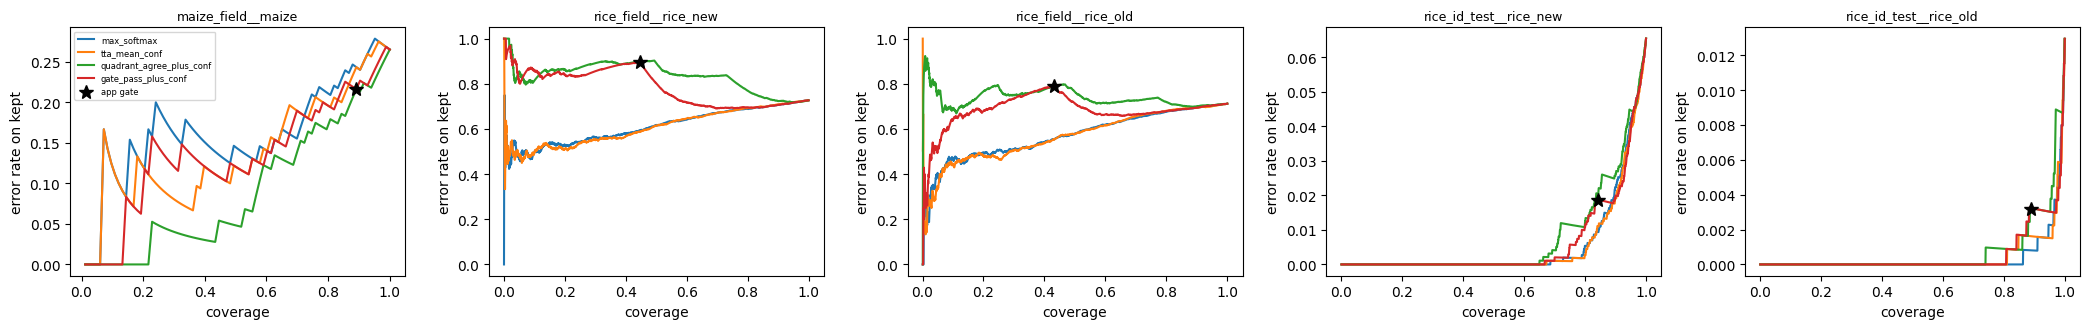


== maize_field__maize: n=83  acc=73.49% [63.1, 81.8]  old-rule=73.49%  gate flags 10.84% and catches 27.27% of errors  ECE 0.235 -> 0.1919
   router correct crop: 93.98 % | wrong crop auto-accepted: 2.41 %

== rice_field__rice_new: n=1500  acc=27.33% [25.1, 29.6]  old-rule=12.0%  gate flags 55.33% and catches 44.95% of errors  ECE 0.4625 -> 0.1181
   router correct crop: 11.27 % | wrong crop auto-accepted: 0.0 %

== rice_field__rice_old: n=1500  acc=28.8% [26.6, 31.1]  old-rule=22.6%  gate flags 56.8% and catches 52.15% of errors  ECE 0.5108 -> 0.0804
   router correct crop: 11.27 % | wrong crop auto-accepted: 0.0 %

== rice_id_test__rice_new: n=1391  acc=93.46% [92.0, 94.6]  old-rule=85.41%  gate flags 15.82% and catches 75.82% of errors  ECE 0.0284 -> 0.0093
   router correct crop: 51.17 % | wrong crop auto-accepted: 0.0 %

== rice_id_test__rice_old: n=1391  acc=98.71% [98.0, 99.2]  old-rule=87.2%  gate flags 11.14% and catches 77.78% of errors  ECE 0.0095 -> 0.0065
   router correc

In [30]:
analysis = {}
for f in sorted(OUT.glob('rows_*.json')):
    key = f.stem[5:]; rows = json.load(open(f))
    classes = models[key.split('__')[1]][2]
    analysis[key] = ex.analyse(rows, classes, reps=1000)
save('analysis.json', analysis)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(analysis), figsize=(4.2 * len(analysis), 3.4), squeeze=False)
for ax, (key, res) in zip(axes[0], analysis.items()):
    rows = json.load(open(OUT / f'rows_{key}.json')); classes = models[key.split('__')[1]][2]
    rows = [r for r in rows if r['true'] in classes]
    y = np.array([classes.index(r['true']) for r in rows]); P = np.array([r['probs'] for r in rows]); correct = P.argmax(1) == y
    for name, s in ex.scores_for(rows, classes).items():
        if name in ('max_softmax', 'tta_mean_conf', 'quadrant_agree_plus_conf', 'gate_pass_plus_conf'):
            cov, risk = ex.risk_coverage(s, correct); ax.plot(cov, risk, label=name)
    g = res['review_gate']
    if g['accuracy_unflagged']['pct'] is not None: ax.plot(g['coverage'], 1 - g['accuracy_unflagged']['pct'] / 100, 'k*', ms=10, label='app gate')
    ax.set_title(key, fontsize=9); ax.set_xlabel('coverage'); ax.set_ylabel('error rate on kept')
axes[0][0].legend(fontsize=6); plt.tight_layout(); plt.savefig(OUT / 'risk_coverage.png', dpi=200); plt.show()
for key, res in analysis.items():
    print(f"\n== {key}: n={res['n']}  acc={res['accuracy']['pct']}% {res['accuracy']['ci95']}  old-rule={res['old_quadrant_vote_accuracy']['pct']}%  "
          f"gate flags {res['review_gate']['flagged']['pct']}% and catches {res['review_gate']['errors_caught']['pct']}% of errors  "
          f"ECE {res['ece_raw']} -> {res['ece_temperature_scaled_crossfit']}")
    if 'router' in res: print('   router correct crop:', res['router']['correct_crop']['pct'], '% | wrong crop auto-accepted:', res['router']['auto_accepted_wrong_crop']['pct'], '%')

In [31]:
   from pathlib import Path
   for f in OUT.glob('rows_*.json'):
       for r in json.load(open(f)):
           if 'file' in r: images_by_key.setdefault(r['tag'], r['file'])
   missing = [k for k, p in images_by_key.items() if not Path(p).exists()]
   print(len(images_by_key), 'photos known;', len(missing), 'files missing')

5865 photos known; 0 files missing


In [32]:
   import kagglehub, re, shutil
   from pathlib import Path
   def norm(s): return re.sub(r"[^a-z0-9]+", "_", str(s).lower()).strip("_")
   src = Path(kagglehub.dataset_download('nirmalsankalana/rice-leaf-disease-image'))
   dest = Path('/content/external/rice_sethy2020/field')
   names = {'bacterial': 'Bacterial Blight', 'blast': 'Blast', 'brown': 'Brown Spot'}
   n = 0
   for f in src.rglob('*'):
       if f.suffix.lower() in ('.jpg', '.jpeg', '.png'):
           folder = norm(f.parent.name)
           for k, v in names.items():
               if k in folder:
                   (dest / v).mkdir(parents=True, exist_ok=True)
                   shutil.copy2(f, dest / v / f"{folder}__{f.name}"); n += 1; break
   print(n, 'rice photos restored')
   for f in OUT.glob('rows_*.json'):
       for r in json.load(open(f)):
           if 'file' in r: images_by_key.setdefault(r['tag'], r['file'])
   missing = [k for k, p in images_by_key.items() if not Path(p).exists()]
   print(len(missing), 'files missing')

Using Colab cache for faster access to the 'rice-leaf-disease-image' dataset.
4624 rice photos restored
0 files missing


## Part 5 — Blind Gemini cross-check (optional)

In [39]:
try:
    from google.colab import userdata
    GEMINI_KEY = userdata.get('GEMINI_API_KEY')
except Exception:
    GEMINI_KEY = None
if not GEMINI_KEY:
    print('No GEMINI_API_KEY secret - Part 5 skipped (everything else is still valid).')
else:
    rows_by_key = {}
    for set_name, model_key in [('maize_field', 'maize'), ('cotton_field', 'cotton'), ('rice_field', 'rice_new')]:
        f = OUT / f'rows_{set_name}__{model_key}.json'
        if f.exists():
            for r in json.load(open(f)): rows_by_key[r['tag']] = r
    recs = ex.gemini_eval(rows_by_key, images_by_key, lambda r: r['true_crop'], GEMINI_KEY, ac.DEFAULT_GEMINI_MODEL,
                          OUT / 'gemini_records.json', per_crop=GEMINI_SAMPLE_PER_CROP, sleep_s=7.0)
    g = {'model': ac.DEFAULT_GEMINI_MODEL, 'overall': ex.gemini_analyse(recs, rows_by_key)}
    for crop in ('Maize', 'Cotton', 'Rice'):
        sub = [r for r in recs if rows_by_key[r['key']]['true_crop'] == crop]
        g[crop] = ex.gemini_analyse(sub, rows_by_key)
    save('gemini_analysis.json', g); print(json.dumps(g['overall'], indent=1))

{
 "assessed": 0,
 "failed_calls": 120
}


## Part 6 — Learned combined gate and conformal guarantees

In [34]:
gem = {}
if (OUT / 'gemini_records.json').exists():
    gem = {r['key']: r['category'] for r in json.load(open(OUT / 'gemini_records.json')) if r.get('ok')}
field_keys = [('maize_field', 'maize'), ('cotton_field', 'cotton'), ('rice_field', 'rice_new')]
gates, sets_X, sets_c = {}, {}, {}
for set_name, model_key in field_keys + [('rice_id_test', 'rice_new')]:
    f = OUT / f'rows_{set_name}__{model_key}.json'
    if not f.exists(): continue
    classes = models[model_key][2]
    rows = [r for r in json.load(open(f)) if r['true'] in classes]
    X, c, names = ex.gate_features(rows, classes)
    y = np.array([classes.index(r['true']) for r in rows]); P = np.array([r['probs'] for r in rows])
    g = {'learned_vs_msp': ex.compare_gates(X, c, names),
         'conformal_sets_90': ex.conformal_sets(P, y, 0.10), 'conformal_sets_95': ex.conformal_sets(P, y, 0.05)}
    sub = [r for r in rows if r['tag'] in gem]
    if len(sub) >= 30:
        Xg, cg, ng = ex.gate_features(sub, classes, gemini=gem)
        Xs, cs, ns_ = ex.gate_features(sub, classes)
        g['with_gemini_subset'] = {'n': len(sub), 'without_gemini': ex.compare_gates(Xs, cs, ns_), 'with_gemini': ex.compare_gates(Xg, cg, ng)}
    gates[f'{set_name}__{model_key}'] = g
    if set_name != 'rice_id_test': sets_X[set_name], sets_c[set_name] = X, c
gates['leave_one_crop_out'] = ex.leave_one_set_out(sets_X, sets_c)
save('gates_conformal.json', gates)
for k, v in gates.items():
    if k == 'leave_one_crop_out': print('\nleave-one-crop-out:', json.dumps(v)); continue
    lv = v['learned_vs_msp']
    print(f"\n== {k}: AURC msp {lv.get('aurc_max_softmax')} vs learned {lv.get('aurc_learned_gate')} (diff CI {lv.get('difference_ci95')}) | "
          f"90% conformal: coverage {v['conformal_sets_90']['empirical_coverage_mean']}, mean set size {v['conformal_sets_90']['mean_set_size']}")


== maize_field__maize: AURC msp 0.1637 vs learned 0.1275 (diff CI [-0.1291, 0.0519]) | 90% conformal: coverage 0.9262, mean set size 2.442

== rice_field__rice_new: AURC msp 0.6105 vs learned 0.441 (diff CI [-0.1919, -0.1475]) | 90% conformal: coverage 0.9062, mean set size 5.499

== rice_id_test__rice_new: AURC msp 0.0055 vs learned 0.0054 (diff CI [-0.0005, 0.0005]) | 90% conformal: coverage 0.9034, mean set size 0.935

leave-one-crop-out: {"maize_field": {"trained_on": ["rice_field"], "aurc_learned": 0.3591, "aurc_max_softmax": 0.1637}, "rice_field": {"trained_on": ["maize_field"], "aurc_learned": 0.8378, "aurc_max_softmax": 0.6105}}


## Part 7 — Few-shot field adaptation (how much field data closes the gap)

In [35]:
if done('few_shot.json'):
    print(json.load(open(OUT / 'few_shot.json')))
else:
    backbone = tf.keras.applications.EfficientNetV2B0(include_top=False, weights='imagenet', input_shape=(224, 224, 3),
                                                       include_preprocessing=True, pooling='avg')
    def pil_array(p):
        try:
            return np.asarray(ex.ImageOps.exif_transpose(Image.open(p)).convert('RGB').resize((224, 224)), dtype=np.float32)
        except Exception:
            return None
    def embed_pairs(pairs, batch=64):
        X, keep = [], []
        for i in range(0, len(pairs), batch):
            arrs = [(pair, pil_array(pair[0])) for pair in pairs[i:i + batch]]
            arrs = [(pair, a) for pair, a in arrs if a is not None]
            if arrs:
                X.append(backbone.predict(np.stack([a for _, a in arrs]), verbose=0)); keep += [pair for pair, _ in arrs]
        return np.vstack(X), keep
    def lab_items(root, rules, per_class=300):
        items, _ = ex.collect_by_keywords(root, rules)
        by = {}
        for p, l in items: by.setdefault(l, []).append(p)
        out = []
        for l, ps in by.items():
            ps = sorted(ps); random.Random(0).shuffle(ps); out += [(p, l) for p in ps[:per_class]]
        return out
    corn_root = Path(kagglehub.dataset_download('smaranjitghose/corn-or-maize-leaf-disease-dataset'))
    cot_root = Path(kagglehub.dataset_download('parthajyotiroyjoy/cotton-plant-disease-dataset'))
    lab = {'maize_field': lab_items(corn_root, [(('gray',), 'Maize_Gray_Leaf_Spot'), (('rust',), 'Maize_Common_Rust'), (('blight',), 'Maize_Blight'), (('healthy',), 'Maize_Healthy')]),
           'cotton_field': lab_items(cot_root, [(('bacterial',), 'Disease_Bacterial_Blight'), (('blight',), 'Disease_Bacterial_Blight'), (('curl',), 'Disease_Curl_Virus'),
                                               (('herbicide',), 'Disease_Herbicide_Damage'), (('redden',), 'Disease_Leaf_Reddening'), (('healthy',), 'Disease_Healthy')]),
           'rice_field': [(p, l) for l in ac.RICE_CLASSES if l.startswith('Rice_') for p in sorted(ex.list_images(DATA / l))[:300]]}
    few = {}
    for set_name, lab_list in lab.items():
        if set_name not in sets or not lab_list: few[set_name] = 'skipped (set or lab data missing)'; continue
        field_list = sets[set_name]; fclasses = set(l for _, l in field_list)
        lab_list = [(p, l) for p, l in lab_list if l in fclasses]
        print(set_name, 'lab', len(lab_list), 'field', len(field_list))
        LX, lab_list = embed_pairs(lab_list); FX, field_list = embed_pairs(list(field_list))
        few[set_name] = {'lab_images': len(lab_list), 'field_images': len(field_list), 'classes': sorted(fclasses),
                         'curve': ex.few_shot_curve(LX, np.array([l for _, l in lab_list]), FX, np.array([l for _, l in field_list]))}
        print(json.dumps(few[set_name]['curve']))
    save('few_shot.json', few)

{'maize_field': {'lab_images': 900, 'field_images': 83, 'classes': ['Maize_Blight', 'Maize_Common_Rust', 'Maize_Gray_Leaf_Spot'], 'curve': {'0': {'accuracy_mean': 0.6867, 'accuracy_sd': 0.0, 'repeats': 1}, '5': {'accuracy_mean': 0.6618, 'accuracy_sd': 0.0208, 'repeats': 5}, '10': {'accuracy_mean': 0.6981, 'accuracy_sd': 0.043, 'repeats': 5}, '20': {'accuracy_mean': 0.6857, 'accuracy_sd': 0.0156, 'repeats': 5}}}, 'cotton_field': 'skipped (set or lab data missing)', 'rice_field': 'skipped (set or lab data missing)'}


## Part 8 — Backbone comparison for rice (3 backbones × 3 seeds, same split)

In [36]:
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
split = json.load(open(OUT / f'rice_seed{RICE_SEEDS[0]}' / 'split.json'))
CL = ac.RICE_CLASSES
def make_ds(pairs, train):
    paths = [p for p, _ in pairs]; labels = [CL.index(l) for _, l in pairs]
    def load(p, y):
        im = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        return tf.cast(tf.image.resize(im, (224, 224)), tf.uint8), y
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)).map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if train: ds = ds.shuffle(len(paths), seed=0)
    return ds.map(lambda x, y: (tf.cast(x, tf.float32), y)).batch(32).prefetch(tf.data.AUTOTUNE)
tr_ds, va_ds = make_ds(split['train'], True), make_ds(split['val'], False)
te_pairs = split['test']; field_pairs = [(str(p), l) for p, l in sets.get('rice_field', [])]
te_ds = make_ds(te_pairs, False)
fi_arr, fi_pairs = [], []
for p, l in field_pairs:
    try:
        fi_arr.append(np.asarray(ex.ImageOps.exif_transpose(Image.open(p)).convert('RGB').resize((224, 224)), dtype=np.float32)); fi_pairs.append((p, l))
    except Exception:
        pass
field_pairs = fi_pairs; fi_ds = tf.data.Dataset.from_tensor_slices(np.stack(fi_arr)).batch(32) if fi_arr else None
cnt = __import__('collections').Counter(l for _, l in split['train'])
cw = {CL.index(l): len(split['train']) / (len(CL) * n) for l, n in cnt.items()}
BACKBONES = {'MobileNetV3Large': lambda: tf.keras.applications.MobileNetV3Large(include_top=False, weights='imagenet', input_shape=(224, 224, 3), include_preprocessing=True, pooling='avg'),
             'EfficientNetV2B0': lambda: tf.keras.applications.EfficientNetV2B0(include_top=False, weights='imagenet', input_shape=(224, 224, 3), include_preprocessing=True, pooling='avg'),
             'ConvNeXtTiny': lambda: tf.keras.applications.ConvNeXtTiny(include_top=False, weights='imagenet', input_shape=(224, 224, 3), include_preprocessing=True, pooling='avg')}
from sklearn.metrics import f1_score
L = tf.keras.layers
def evaluate(model, ds, pairs):
    if ds is None or not pairs: return None
    pred = model.predict(ds, verbose=0).argmax(1); y = np.array([CL.index(l) for _, l in pairs])
    present = sorted(set(y.tolist()))
    return {'accuracy': float((pred == y).mean()), 'macro_f1': float(f1_score(y, pred, labels=present, average='macro', zero_division=0)), 'n': int(len(y))}
for name, make in BACKBONES.items():
    for seed in RICE_SEEDS:
        fname = f'backbone_{name}_seed{seed}.json'
        if done(fname): print('done', fname); continue
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        base = make(); base.trainable = False
        aug = tf.keras.Sequential([L.RandomFlip('horizontal_and_vertical'), L.RandomRotation(0.08), L.RandomZoom(0.15), L.RandomContrast(0.2)])
        inp = L.Input((224, 224, 3)); x = base(aug(inp), training=False); x = L.Dropout(0.3)(x)
        out = L.Dense(len(CL), activation='softmax', dtype='float32')(x); model = tf.keras.Model(inp, out)
        es = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]
        t0 = time.time()
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        model.fit(tr_ds, validation_data=va_ds, epochs=10, class_weight=cw, callbacks=es, verbose=0)
        base.trainable = True
        for layer in base.layers[:-30]: layer.trainable = False
        for layer in base.layers:
            if isinstance(layer, (L.BatchNormalization, L.LayerNormalization)): layer.trainable = False
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        model.fit(tr_ds, validation_data=va_ds, epochs=6, class_weight=cw, callbacks=es, verbose=0)
        train_min = (time.time() - t0) / 60
        x1 = np.random.default_rng(0).uniform(0, 255, (1, 224, 224, 3)).astype('float32')
        latency = None
        try:   # time a CPU copy of the trained model (GPU/XLA variables cannot be read from the CPU)
            with tf.device('/CPU:0'):
                cpu_model = tf.keras.models.clone_model(model); cpu_model.set_weights(model.get_weights())
                for _ in range(3): cpu_model(x1, training=False)
                ts = []
                for _ in range(20):
                    s = time.perf_counter(); cpu_model(x1, training=False); ts.append(time.perf_counter() - s)
            latency = round(1000 * float(np.median(ts)), 1); del cpu_model
        except Exception as e:
            print('latency not measured:', str(e)[:150])
        r = {'backbone': name, 'seed': seed, 'params_million': round(model.count_params() / 1e6, 2), 'train_minutes': round(train_min, 1),
             'cpu_latency_ms_median_mixed_precision': latency, 'test': evaluate(model, te_ds, te_pairs), 'field': evaluate(model, fi_ds, field_pairs)}
        save(fname, r); print(json.dumps(r))
mixed_precision.set_global_policy('float32')
summary = {}
for name in BACKBONES:
    rs = [json.load(open(OUT / f'backbone_{name}_seed{s}.json')) for s in RICE_SEEDS if done(f'backbone_{name}_seed{s}.json')]
    def ms(key, sub):
        v = [r[key][sub] for r in rs if r.get(key)]
        return [round(float(np.mean(v)), 4), round(float(np.std(v, ddof=1)), 4) if len(v) > 1 else None] if v else None
    summary[name] = {'runs': len(rs), 'params_million': rs[0]['params_million'] if rs else None,
                     'cpu_latency_ms_mixed_precision': next((r['cpu_latency_ms_median_mixed_precision'] for r in rs if r.get('cpu_latency_ms_median_mixed_precision')), None),
                     'test_accuracy_mean_sd': ms('test', 'accuracy'), 'test_macro_f1_mean_sd': ms('test', 'macro_f1'),
                     'field_accuracy_mean_sd': ms('field', 'accuracy')}
save('backbones_summary.json', summary); print(json.dumps(summary, indent=1))

done backbone_MobileNetV3Large_seed42.json
done backbone_MobileNetV3Large_seed7.json
done backbone_MobileNetV3Large_seed2024.json
done backbone_EfficientNetV2B0_seed42.json
done backbone_EfficientNetV2B0_seed7.json
done backbone_EfficientNetV2B0_seed2024.json
done backbone_ConvNeXtTiny_seed42.json
done backbone_ConvNeXtTiny_seed7.json
done backbone_ConvNeXtTiny_seed2024.json
{
 "MobileNetV3Large": {
  "runs": 3,
  "params_million": 3.0,
  "cpu_latency_ms_mixed_precision": 294.4,
  "test_accuracy_mean_sd": [
   0.919,
   0.0017
  ],
  "test_macro_f1_mean_sd": [
   0.8736,
   0.0039
  ],
  "field_accuracy_mean_sd": null
 },
 "EfficientNetV2B0": {
  "runs": 3,
  "params_million": 5.93,
  "cpu_latency_ms_mixed_precision": 482.6,
  "test_accuracy_mean_sd": [
   0.9125,
   0.0054
  ],
  "test_macro_f1_mean_sd": [
   0.8627,
   0.0085
  ],
  "field_accuracy_mean_sd": null
 },
 "ConvNeXtTiny": {
  "runs": 3,
  "params_million": 27.83,
  "cpu_latency_ms_mixed_precision": 1650.4,
  "test_accurac

In [37]:
# Package everything (also stays in My Drive/agri_results_v2) and download
import platform
save('environment.json', {'repo_commit': COMMIT, 'tensorflow': tf.__version__, 'python': platform.python_version(),
                          'gpu': [d.name for d in tf.config.list_physical_devices('GPU')], 'finished_utc': time.strftime('%Y-%m-%d %H:%M', time.gmtime()),
                          'settings': {'RICE_SEEDS': RICE_SEEDS, 'GEMINI_SAMPLE_PER_CROP': GEMINI_SAMPLE_PER_CROP,
                                       'MAX_IMAGES_PER_SET': MAX_IMAGES_PER_SET, 'DUP_THRESHOLD': DUP_THRESHOLD}})
zpath = '/content/agri_results_v2.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob('*'):
        if f.is_file() and not (f.suffix == '.tflite' and 'seed' in str(f) and f'seed{RICE_SEEDS[0]}' not in str(f)):
            z.write(f, f.relative_to(OUT.parent))
print('zip size MB:', round(os.path.getsize(zpath) / 1e6, 1))
from google.colab import files
files.download(zpath)

zip size MB: 22.8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>